# FIFA World Cup 2026: Linear Regression 2.1

**Analytic question:** How well can eight pre-match predictors explain and predict the goal difference between opposing teams?

This analysis uses 104 matches to build a multiple linear regression model. The first 83 matches are used for training and the remaining 21 for testing. Performance is compared with a baseline that predicts the mean goal difference from the training data.

Match results are used to calculate historical performance measures, while FIFA ranking points provide a measure of team strength. The analysis also examines regression coefficients and residual diagnostics.

**Input files:**
- `World_Cup_2026_Match_Data.csv`: raw fixtures and results
- `Regression_2_1_Dataset.csv`: prepared ranking differences and comparison data

Both files should be kept in the same folder as this notebook.

In [1]:
import os
import re
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Locating the Input Files

Keep both CSV files in the same folder as this notebook. The code checks their exact filenames.

In [2]:
from pathlib import Path

RAW_FILE = "World_Cup_2026_Match_Data.csv"
PREPARED_FILE = "Regression_2_1_Dataset.csv"

raw_path = Path.cwd() / RAW_FILE
prepared_path = Path.cwd() / PREPARED_FILE

if not raw_path.is_file():
    raise FileNotFoundError(
        f"Cannot find {RAW_FILE}. Keep it in the same folder as the notebook."
    )

if not prepared_path.is_file():
    raise FileNotFoundError(
        f"Cannot find {PREPARED_FILE}. Keep it in the same folder as the notebook."
    )

print("Raw file found:", raw_path.name)
print("Prepared file found:", prepared_path.name)

Raw file found: World_Cup_2026_Match_Data.csv
Prepared file found: Regression_2_1_Dataset.csv


## 2. Loading the Raw Fixtures

The raw file is a spreadsheet-style export. It contains section titles (GROUP STAGE, ROUND OF 32 and so on), repeated header rows and many match statistics columns. It is read without a header so that every row can be inspected.

In [3]:
raw = pd.read_csv(raw_path, header=None)

print("Raw shape:", raw.shape)
raw.head(6)

Raw shape: (121, 28)


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,GROUP STAGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,GOALS,NaN,NaN,NaN,CARDS,...,NaN,NaN,xG,NaN,SHOTS,NaN,SHOTS ON\nTARGET,NaN,FOULS,NaN
2,Date,Team 1,Result,NaN,Team 2,1H,NaN,2H,NaN,YEL,...,NaN,T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11/06/2026,Mexico,2,0,South Africa,1,0.0,1,0.0,1,...,1.0,4,1.46,0.07,16,3.0,4,2.0,12,11.0
4,12/06/2026,South Korea,2,1,Czech Republic,0,0.0,2,1.0,1,...,5.0,9,2.30,0.83,15,7.0,6,4.0,9,16.0
5,12/06/2026,Canada,1,1,Bosnia & Herzegovina,0,1.0,1,0.0,2,...,4.0,13,1.25,0.98,13,8.0,4,3.0,10,20.0


## 3. Extracting the Matches

Match rows start with a date in `dd/mm/yyyy` form. Rows that contain only a section title set the current stage. Column 1 is Team 1 (listed as Home), columns 2 and 3 are the two scores, and column 4 is Team 2 (listed as Away). Header and statistics-title rows are ignored.

In [4]:
date_pattern = re.compile(r"\d{2}/\d{2}/\d{4}")

stage = None
records = []

for _, row in raw.iterrows():
    first = str(row[0]).strip()
    if date_pattern.fullmatch(first):
        records.append({
            "Stage": stage,
            "Date": first,
            "Home": row[1],
            "Home_Score": str(row[2]),
            "Away_Score": str(row[3]),
            "Away": row[4],
        })
    elif pd.notna(row[0]) and first != "Date" and pd.isna(row[1]):
        stage = first

matches = pd.DataFrame(records)

print("Matches found:", len(matches))
print(matches["Stage"].value_counts())
matches.head()

Matches found: 103
Stage
GROUP STAGE       72
ROUND OF 32       16
ROUND OF 16        8
QUARTER FINALS     4
SEMI FINALS        2
FINAL              1
Name: count, dtype: int64


,Stage,Date,Home,Home_Score,Away_Score,Away
0,GROUP STAGE,11/06/2026,Mexico,2,0,South Africa
1,GROUP STAGE,12/06/2026,South Korea,2,1,Czech Republic
2,GROUP STAGE,12/06/2026,Canada,1,1,Bosnia & Herzegovina
3,GROUP STAGE,13/06/2026,USA,4,1,Paraguay
4,GROUP STAGE,13/06/2026,Qatar,1,1,Switzerland


## 4. Cleaning Scores and Team Names

In knockout matches decided by a penalty shoot-out, the raw file puts a `p` next to the score of the shoot-out winner (for example `1p`). The number is the score before the shoot-out, so the `p` is removed and shoot-out goals are never counted. Goal_Difference is Home goals minus Away goals.

Team names are changed to the spelling used in the prepared dataset so that the two files can be matched later.

In [5]:
shootouts = matches[
    matches["Home_Score"].str.contains("p") | matches["Away_Score"].str.contains("p")
]
print("Matches with a penalty shoot-out marker:")
print(shootouts[["Stage", "Home", "Home_Score", "Away_Score", "Away"]])

Matches with a penalty shoot-out marker:
          Stage         Home Home_Score Away_Score      Away
74  ROUND OF 32      Germany          1         1p  Paraguay
75  ROUND OF 32  Netherlands          1         1p   Morocco
85  ROUND OF 32    Australia          1         1p     Egypt
95  ROUND OF 16  Switzerland         p0          0  Colombia


In [6]:
name_map = {
    "Bosnia & Herzegovina": "Bosnia–Herz",
    "Cape Verde": "Cabo Verde",
    "Curacao": "Curaçao",
    "Czech Republic": "Czechia",
    "D.R. Congo": "Congo DR",
    "Iran": "IR Iran",
    "Ivory Coast": "Côte d'Ivoire",
    "South Korea": "Korea Republic",
    "Turkey": "Türkiye",
}

matches["Home_Goals"] = matches["Home_Score"].str.replace("p", "", regex=False).astype(int)
matches["Away_Goals"] = matches["Away_Score"].str.replace("p", "", regex=False).astype(int)
matches["Goal_Difference"] = matches["Home_Goals"] - matches["Away_Goals"]

matches["Home"] = matches["Home"].replace(name_map)
matches["Away"] = matches["Away"].replace(name_map)
matches["Date"] = pd.to_datetime(matches["Date"], format="%d/%m/%Y")

matches = matches.drop(columns=["Home_Score", "Away_Score"])
matches[["Stage", "Home", "Away", "Home_Goals", "Away_Goals", "Goal_Difference"]].head()

,Stage,Home,Away,Home_Goals,Away_Goals,Goal_Difference
0,GROUP STAGE,Mexico,South Africa,2,0,2
1,GROUP STAGE,Korea Republic,Czechia,2,1,1
2,GROUP STAGE,Canada,Bosnia–Herz,1,1,0
3,GROUP STAGE,USA,Paraguay,4,1,3
4,GROUP STAGE,Qatar,Switzerland,1,1,0


## 5. Completing the Dataset: Third-Place Match

The fixtures file contains 103 matches because it omits the third-place match. The France v England match dated 18 July 2026 is added using the goal difference of −2 recorded in the prepared dataset, bringing the total to 104 matches.

Its individual scores are not needed for later history calculations because neither team plays again afterwards. The match is placed before the final, and each match receives a unique Match_ID.

In [7]:
third_place = pd.DataFrame([{
    "Stage": "THIRD PLACE",
    "Date": pd.Timestamp("2026-07-18"),
    "Home": "France",
    "Away": "England",
    "Home_Goals": np.nan,
    "Away_Goals": np.nan,
    "Goal_Difference": -2,
}])

is_final = matches["Stage"] == "FINAL"
matches = pd.concat(
    [matches[~is_final], third_place, matches[is_final]],
    ignore_index=True
)
matches["Match_ID"] = matches.index + 1

print("Total matches:", len(matches))
matches[["Match_ID", "Stage", "Home", "Away", "Goal_Difference"]].tail(4)

Total matches: 104


,Match_ID,Stage,Home,Away,Goal_Difference
100,101,SEMI FINALS,France,Spain,-2
101,102,SEMI FINALS,England,Argentina,-1
102,103,THIRD PLACE,France,England,-2
103,104,FINAL,Spain,Argentina,1


## 6. Stage and Host Indicators

Knockout is 0 for group-stage matches and 1 for every other stage. Host_Diff compares whether the teams represent Mexico, Canada or USA. It equals 1 when only Home is a host nation, −1 when only Away is a host nation, and 0 when both or neither are hosts.

In [8]:
matches["Knockout"] = (matches["Stage"] != "GROUP STAGE").astype(int)

hosts = ["Mexico", "Canada", "USA"]
matches["Host_Diff"] = (
    matches["Home"].isin(hosts).astype(int)
    - matches["Away"].isin(hosts).astype(int)
)

print(matches["Knockout"].value_counts().sort_index())
print(matches["Host_Diff"].value_counts().sort_index())

Knockout
0    72
1    32
Name: count, dtype: int64
Host_Diff
-1     4
 0    89
 1    11
Name: count, dtype: int64


### Handling Missing Historical Values

On matchday 1 (the first 24 matches) neither team has played a World Cup 2026 match, so no tournament history exists for either side. These history values are not observed performance, and the model does not treat them as "zero goals" or "zero wins".

Every history predictor is a difference (Home minus Away). Each matchday-1 game pairs two teams who both lack history, so the difference is set to 0, meaning no relative information about either team. All 104 matches are kept. For these matches the model relies on Rank_Points_Diff, Host_Diff and Knockout, which are available before kick-off.
After each team's first match, historical measures become available. Early estimates are based on only one or two matches and may be unstable. The limited amount of history may contribute to uncertainty in the historical predictor coefficients.

## 7. Building the History Predictors

The matches are processed in playing order. For each match, every team's record from its earlier matches only is used to calculate five measures: average goals scored, average goals conceded, win rate, clean-sheet rate and the goal difference of its previous match. Each measure is expressed as Home minus Away. A team's record is updated only after the match's predictors have been saved, so the current match is never included.

In [9]:
history = {}
feature_rows = []


def pre_match(team):
    h = history.get(team)
    if h is None:
        return {"gf": 0, "ga": 0, "win": 0, "clean": 0, "lastgd": 0}
    n = h["played"]
    return {
        "gf": h["gf"] / n,
        "ga": h["ga"] / n,
        "win": h["wins"] / n,
        "clean": h["clean"] / n,
        "lastgd": h["lastgd"],
    }


for _, m in matches.iterrows():
    home, away = pre_match(m["Home"]), pre_match(m["Away"])
    feature_rows.append({
        "Past_Avg_Scored_Diff": home["gf"] - away["gf"],
        "Past_Avg_Conceded_Diff": home["ga"] - away["ga"],
        "Past_Win_Rate_Diff": home["win"] - away["win"],
        "Past_Clean_Sheet_Rate_Diff": home["clean"] - away["clean"],
        "Last_Match_GD_Diff": home["lastgd"] - away["lastgd"],
    })

    # Update records only AFTER this match's predictors were saved.
    # The third-place match has no individual scores and is never used as history.
    if pd.isna(m["Home_Goals"]):
        continue
    for team, gf, ga in [(m["Home"], m["Home_Goals"], m["Away_Goals"]),
                         (m["Away"], m["Away_Goals"], m["Home_Goals"])]:
        h = history.setdefault(team, {"played": 0, "gf": 0, "ga": 0,
                                      "wins": 0, "clean": 0, "lastgd": 0})
        h["played"] += 1
        h["gf"] += gf
        h["ga"] += ga
        h["lastgd"] = gf - ga
        h["wins"] += int(gf > ga)
        h["clean"] += int(ga == 0)

matches = pd.concat([matches, pd.DataFrame(feature_rows)], axis=1)
matches[["Match_ID", "Home", "Away", "Past_Avg_Scored_Diff", "Past_Win_Rate_Diff"]].iloc[[0, 24, 60, 100]]

,Match_ID,Home,Away,Past_Avg_Scored_Diff,Past_Win_Rate_Diff
0,1,Mexico,South Africa,0.000000,0.000000
24,25,Czechia,South Africa,1.000000,0.000000
60,61,Norway,France,0.500000,0.000000
100,101,France,Spain,0.833333,0.166667


## 8. Incorporating FIFA Ranking Points

FIFA ranking points are not included in the fixtures file. Ranking point differences from the 11 June 2026 edition were collected earlier and stored in the prepared dataset. They are merged here using the Home and Away team names.

Rank_Points_Diff is calculated as Home points minus Away points. It provides a consistent measure of relative team strength across the matches.

FIFA published this edition on 11 June 2026, hours before the opening match, and the next edition was not due until 20 July 2026, after the final. The points were therefore available before every match.

In [10]:
predictors = [
    "Past_Avg_Scored_Diff",
    "Past_Avg_Conceded_Diff",
    "Past_Win_Rate_Diff",
    "Rank_Points_Diff",
    "Past_Clean_Sheet_Rate_Diff",
    "Last_Match_GD_Diff",
    "Host_Diff",
    "Knockout"
]

prepared = pd.read_csv(prepared_path)
rank_points = prepared[["Home", "Away", "Rank_Points_Diff"]]

df = matches.merge(rank_points, on=["Home", "Away"], how="left", validate="one_to_one")
df = df[["Match_ID", "Date", "Stage", "Home", "Away",
         "Home_Goals", "Away_Goals", "Goal_Difference"] + predictors]

assert len(df) == 104, "Expected 104 matches"
assert df["Rank_Points_Diff"].notna().all(), "Some matches have no ranking points"

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (104, 16)


,Match_ID,Date,Stage,Home,Away,Home_Goals,Away_Goals,Goal_Difference,Past_Avg_Scored_Diff,Past_Avg_Conceded_Diff,Past_Win_Rate_Diff,Rank_Points_Diff,Past_Clean_Sheet_Rate_Diff,Last_Match_GD_Diff,Host_Diff,Knockout
0,1,2026-06-11,GROUP STAGE,Mexico,South Africa,2.0,0.0,2,0.0,0.0,0.0,259.10,0.0,0.0,1,0
1,2,2026-06-12,GROUP STAGE,Korea Republic,Czechia,2.0,1.0,1,0.0,0.0,0.0,85.89,0.0,0.0,0,0
2,3,2026-06-12,GROUP STAGE,Canada,Bosnia–Herz,1.0,1.0,0,0.0,0.0,0.0,172.26,0.0,0.0,1,0
3,4,2026-06-13,GROUP STAGE,USA,Paraguay,4.0,1.0,3,0.0,0.0,0.0,165.88,0.0,0.0,1,0
4,5,2026-06-13,GROUP STAGE,Qatar,Switzerland,1.0,1.0,0,0.0,0.0,0.0,-199.75,0.0,0.0,0,0


## 9. Cross-Check Against the Prepared Dataset

The rebuilt target and predictors are compared against the prepared dataset. Differences below 0.01 may reflect rounding. The output also checks whether the same 83 fixtures form the training set and whether match IDs differ.

In [11]:
check = df.merge(prepared, on=["Home", "Away"], suffixes=("", "_prepared"), validate="one_to_one")

for col in ["Goal_Difference"] + predictors:
    max_diff = (check[col] - check[col + "_prepared"]).abs().max()
    print(f"{col:28s} max difference: {max_diff:.4f}")

same_training = (set(zip(df["Home"][:83], df["Away"][:83]))
                 == set(zip(prepared["Home"][:83], prepared["Away"][:83])))
print("\nSame 83 training matches:", same_training)
print("Matches with a different Match_ID:", int((check["Match_ID"] != check["Match_ID_prepared"]).sum()))

Goal_Difference              max difference: 0.0000
Past_Avg_Scored_Diff         max difference: 0.0000
Past_Avg_Conceded_Diff       max difference: 0.0000
Past_Win_Rate_Diff           max difference: 0.0000
Rank_Points_Diff             max difference: 0.0000
Past_Clean_Sheet_Rate_Diff   max difference: 0.0000
Last_Match_GD_Diff           max difference: 0.0000
Host_Diff                    max difference: 0.0000
Knockout                     max difference: 0.0000

Same 83 training matches: True
Matches with a different Match_ID: 18


## 10. Checking Data Quality

The dataset is checked for missing values in the target and predictors, repeated Home–Away pairings, team coverage and unique match identifiers.

The checks show 48 teams, 104 unique Match_ID values, no repeated Home–Away pairings and no missing modelling values. Individual scores for the added third-place match remain missing, but these columns are excluded from the regression.

In [12]:
print("Missing values in key columns:", int(df[["Goal_Difference"] + predictors].isna().sum().sum()))
print("Duplicate matches:", df.duplicated(subset=["Home", "Away"]).sum())
print("Unique teams:", pd.concat([df["Home"], df["Away"]]).nunique())
print("Same teams in Home and Away:", set(df["Home"]) == set(df["Away"]))
print("Unique match IDs:", df["Match_ID"].nunique())

Missing values in key columns: 0
Duplicate matches: 0
Unique teams: 48
Same teams in Home and Away: True
Unique match IDs: 104


### Data Sources and Dataset Structure

Match results and tournament stages come from The Stats Don't Lie World Cup 2026 fixtures file. The missing third-place record and FIFA ranking point differences are supplied through the prepared dataset. Ranking points were collected from the official FIFA men's ranking.

The rebuilt dataset contains 104 matches and eight predictors. Match_ID, Date, Stage, Home, Away, Home_Goals and Away_Goals identify or describe matches and are excluded from the predictor matrix.

Goal_Difference is the target variable, calculated as Home goals minus Away goals before any penalty shoot-out. Home and Away describe team listing order rather than the match venue.

### Goal Difference Summary
Descriptive statistics show the number of matches, mean, standard deviation, minimum, maximum and quartiles of goal difference. Positive values favour the team listed as Home, while negative values favour Away.

In [13]:
df["Goal_Difference"].describe()

count    104.000000
mean       0.480769
std        2.024034
min       -4.000000
25%       -1.000000
50%        0.000000
75%        2.000000
max        6.000000
Name: Goal_Difference, dtype: float64

### Interpretation of Descriptive Statistics

Across 104 matches, the mean goal difference was 0.48 and the median was 0. The standard deviation was 2.02, with values ranging from −4 to 6.

Teams listed as Home scored slightly more goals on average. This does not establish a home-ground advantage because Home and Away refer to the teams' listing order.

### Distribution of Goal Difference
The bar chart shows the number of matches at each goal difference. It helps identify common results and the frequency of large winning margins.

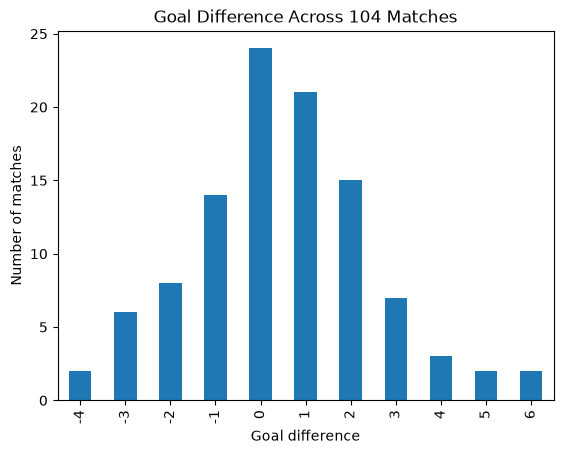

In [14]:
df["Goal_Difference"].value_counts().sort_index().plot.bar()

plt.xlabel("Goal difference")
plt.ylabel("Number of matches")
plt.title("Goal Difference Across 104 Matches")
plt.show()

### Interpretation of the Goal Difference Distribution

A goal difference of zero was most frequent, occurring in 24 matches. Most matches had goal differences between −2 and 2, while larger winning margins were less common.

Matches decided by penalty shoot-outs remain level in this measure because shoot-out goals are excluded.

### Checking the Knockout Indicator

Knockout is coded as 0 for group-stage matches and 1 for knockout matches. The counts are checked to confirm 72 group-stage matches and 32 knockout matches.

In [15]:
df["Knockout"].value_counts().sort_index()

Knockout
0    72
1    32
Name: count, dtype: int64

### Selecting the Eight Predictors

The model uses five historical performance differences, FIFA ranking points difference, Host_Diff and Knockout. The number of matches, predictors and missing values is checked below.

In [16]:
predictors = [
    "Past_Avg_Scored_Diff",
    "Past_Avg_Conceded_Diff",
    "Past_Win_Rate_Diff",
    "Rank_Points_Diff",
    "Past_Clean_Sheet_Rate_Diff",
    "Last_Match_GD_Diff",
    "Host_Diff",
    "Knockout"
]

print("Matches:", len(df))
print("Predictors:", len(predictors))
print("Missing values:", df[predictors].isna().sum().sum())

Matches: 104
Predictors: 8
Missing values: 0


### Predictor Selection

Each predictor is a Home minus Away difference (except Knockout) and uses only information available before the match.

| Predictor | What it measures | Expected sign | Reason |
|---|---|---|---|
| Past_Avg_Scored_Diff | Earlier goals scored per match | + | Stronger attack, higher goal difference |
| Past_Avg_Conceded_Diff | Earlier goals conceded per match | − | Weaker defence, lower goal difference |
| Past_Win_Rate_Diff | Earlier win rate | + | Recent winners may be stronger |
| Rank_Points_Diff | FIFA ranking points (11 June 2026) | + | Pre-tournament strength |
| Past_Clean_Sheet_Rate_Diff | Earlier clean-sheet rate | + | Defensive solidity |
| Last_Match_GD_Diff | Previous-match goal difference | + | Short-term form |
| Host_Diff | Host-nation status | + | Possible home support and travel advantage |
| Knockout | 0 = group, 1 = knockout | No clear direction | Stage control; knockout games may be tighter |

First-match history differences are 0 because neither team has history (see Handling Missing Historical Values).

### Chronological Training and Testing Split

The eight predictors form X, and goal difference forms y. The first 83 matches are used for training and the remaining 21 for testing, following the fixture order.

This split evaluates predictions for later matches using a model fitted to earlier matches. The training set contains 72 group-stage matches and 11 knockout matches. All 21 test matches are knockout matches, so the test results mainly assess performance during the later tournament stages.

Historical predictors for each test match use results available before that match, including earlier test matches once their results are known. The fitted regression model remains unchanged during testing.

In [17]:
X = df[predictors]
y = df["Goal_Difference"]

X_train = X.iloc[:83]
X_test = X.iloc[83:]

y_train = y.iloc[:83]
y_test = y.iloc[83:]

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))

Training matches: 83
Testing matches: 21


### Predictor Summary (Training Matches)

The table shows each predictor's spread and its correlation with goal difference, using training matches only.

In [18]:
summary = X_train.describe().loc[["mean", "std", "min", "max"]].T.round(2)
summary["Corr_with_GD"] = X_train.corrwith(y_train).round(2)
summary

,mean,std,min,max,Corr_with_GD
Past_Avg_Scored_Diff,0.04,1.41,-4.50,6.0,0.14
Past_Avg_Conceded_Diff,-0.15,1.38,-6.00,3.0,-0.33
Past_Win_Rate_Diff,0.01,0.39,-1.00,1.0,0.18
Rank_Points_Diff,59.37,237.54,-489.53,503.6,0.66
Past_Clean_Sheet_Rate_Diff,-0.02,0.45,-1.00,1.0,0.27
Last_Match_GD_Diff,0.45,2.46,-8.00,8.0,0.25
Host_Diff,0.05,0.38,-1.00,1.0,0.27
Knockout,0.13,0.34,0.00,1.0,0.07


### Interpretation of Predictor Summary

Rank_Points_Diff has the strongest correlation with goal difference (0.66). Past_Avg_Conceded_Diff is negative (−0.33), as expected, since conceding more goals lowers goal difference. Clean-sheet rate, Host_Diff and Last_Match_GD_Diff are weakly positive (about 0.25 to 0.27). Past_Win_Rate_Diff (0.18), Past_Avg_Scored_Diff (0.14) and Knockout (0.07) are weak. Most predictors carry little linear signal on their own, These correlations describe individual linear relationships and do not establish each predictor's significance when the other predictors are included.

### Training the Linear Regression Model

The linear regression model is fitted to the 83 training matches using all eight predictors. It then predicts goal differences for the 21 test matches.

The first five predictions are displayed alongside the actual goal differences.

In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions
}).head()

,Actual,Predicted
83,1,1.087474
84,2,0.494851
85,0,0.513686
86,1,2.126099
87,1,1.757403


### Evaluating Model Performance
MAE, RMSE and R² measure prediction performance on the test matches. Lower MAE and RMSE indicate smaller errors, while higher R² indicates better performance.

In [20]:
print("MAE:", round(mean_absolute_error(y_test, predictions), 3))
print("RMSE:", round(mean_squared_error(y_test, predictions) ** 0.5, 3))
print("R²:", round(r2_score(y_test, predictions), 3))

MAE: 1.214
RMSE: 1.53
R²: 0.002


### Comparing Against a Baseline
The baseline predicts the training-set mean goal difference for every test match. Its evaluation scores are compared with the regression scores to assess whether the model improves on this simple prediction.

In [21]:
baseline = [y_train.mean()] * len(y_test)

print("Baseline MAE:", round(mean_absolute_error(y_test, baseline), 3))
print("Baseline RMSE:", round(mean_squared_error(y_test, baseline) ** 0.5, 3))
print("Baseline R²:", round(r2_score(y_test, baseline), 3))

Baseline MAE: 1.426
Baseline RMSE: 1.747
Baseline R²: -0.302


### Interpretation of Test Performance

The regression achieved a test MAE of 1.214 goals, RMSE of 1.530 and R² of 0.002. The training-mean baseline achieved MAE of 1.426, RMSE of 1.747 and R² of −0.302.

The regression had lower prediction errors than the baseline. However, its test R² was close to zero, indicating limited predictive performance and only a slight improvement over predicting the test-set mean.

### Exploratory Comparison: Ranking Points Only

To check whether eight predictors are needed, a model using only Rank_Points_Diff is fitted on the same training matches and evaluated on the same test matches.

In [22]:
simple = LinearRegression()
simple.fit(X_train[["Rank_Points_Diff"]], y_train)
simple_pred = simple.predict(X_test[["Rank_Points_Diff"]])

print("Rank-only MAE:", round(mean_absolute_error(y_test, simple_pred), 3))
print("Rank-only RMSE:", round(mean_squared_error(y_test, simple_pred) ** 0.5, 3))
print("Rank-only R²:", round(r2_score(y_test, simple_pred), 3))

Rank-only MAE: 1.173
Rank-only RMSE: 1.466
Rank-only R²: 0.084


### Comparing Ranking-Only and Eight-Predictor Models

The ranking-only model achieved test MAE of 1.173, RMSE of 1.466 and R² of 0.084. These results were slightly better than the eight-predictor model, which achieved MAE of 1.214, RMSE of 1.530 and R² of 0.002.

The additional predictors did not improve performance on this test set. The gap between training R² (0.495) and test R² (0.002) may reflect overfitting, differences between tournament stages, or both.

The eight-predictor model remains the main model required by the assignment. The ranking-only comparison is exploratory and uses the same test set, so it is not an independent validation. With only 21 test matches, the difference should be interpreted cautiously.

### Plotting Actual and Predicted Values
The scatter plot compares actual goal differences with predictions. The dashed line represents perfect predictions, so points closer to it indicate smaller errors.

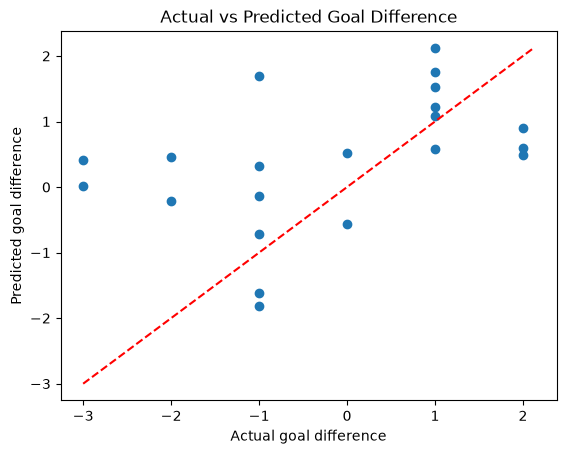

In [23]:
plt.scatter(y_test, predictions)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual goal difference")
plt.ylabel("Predicted goal difference")
plt.title("Actual vs Predicted Goal Difference")
plt.show()

### Interpretation of Actual and Predicted Values

Predicted goal differences range from approximately −1.81 to 2.13, while actual test values range from −3 to 2.

Several points lie away from the perfect-prediction line, showing prediction errors. The test MAE was 1.214 goals, and the model performed better than the training-mean baseline. However, its test R² of 0.002 indicates limited predictive performance.

### Examining the Largest Test Errors
The table lists the five test matches with the largest absolute prediction errors (actual minus predicted goal difference).

In [24]:
errors = df.iloc[83:][["Match_ID", "Home", "Away", "Goal_Difference"]].copy()
errors["Predicted"] = predictions.round(2)
errors["Error"] = (errors["Goal_Difference"] - errors["Predicted"]).round(2)

errors.reindex(errors["Error"].abs().sort_values(ascending=False).index).head(5)

,Match_ID,Home,Away,Goal_Difference,Predicted,Error
93,94,USA,Belgium,-3,0.41,-3.41
88,89,Canada,Morocco,-3,0.01,-3.01
90,91,Brazil,Norway,-1,1.69,-2.69
102,103,France,England,-2,0.46,-2.46
100,101,France,Spain,-2,-0.21,-1.79


### Interpretation of Test Errors

The model was within one goal in 11 of the 21 test matches. For the 19 matches that were not draws, the sign of the predicted goal difference matched the actual winner in 14. The largest misses were USA v Belgium (actual −3, predicted 0.41), Canada v Morocco (actual −3, predicted 0.01) and Brazil v Norway (actual −1, predicted 1.69). Two of the three involve host nations, which the positive Host_Diff coefficient (0.82) favours. This may partly reflect over-crediting hosts, but with so few matches it is only a possibility.

### Statistical Regression Summary

An ordinary least squares model is fitted to the training data. The summary reports training R², adjusted R², coefficients, p-values and confidence intervals.

In [25]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:        Goal_Difference   R-squared:                       0.495
Model:                            OLS   Adj. R-squared:                  0.441
Method:                 Least Squares   F-statistic:                     9.082
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.33e-08
Time:                        22:09:39   Log-Likelihood:                -150.38
No. Observations:                  83   AIC:                             318.8
Df Residuals:                      74   BIC:                             340.5
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

### Interpreting the OLS Results

Training R² was 0.495 and adjusted R² was 0.441. The overall F-test p-value was approximately 1.33 × 10⁻⁸, indicating an overall association between the predictors and goal difference under the model's assumptions.

Rank_Points_Diff was the only predictor statistically significant at the 5% level (p < 0.001). The remaining predictors were not significant at this level.

The Jarque–Bera p-value was 0.522, so this test did not provide sufficient evidence to reject residual normality. Durbin–Watson was approximately 2.27, but this does not establish independence because teams appear in multiple matches.

### Examining Regression Coefficients

The coefficients show the estimated change in goal difference for a one-unit increase in each predictor, holding the other predictors constant. The intercept is the predicted value when all predictors equal zero.

In [26]:
coefficients = pd.DataFrame({
    "Predictor": predictors,
    "Coefficient": model.coef_
})

print("Intercept:", round(model.intercept_, 3))
coefficients.round(3)

Intercept: 0.322


,Predictor,Coefficient
0,Past_Avg_Scored_Diff,0.064
1,Past_Avg_Conceded_Diff,-0.207
2,Past_Win_Rate_Diff,-0.811
3,Rank_Points_Diff,0.005
4,Past_Clean_Sheet_Rate_Diff,0.580
5,Last_Match_GD_Diff,-0.010
6,Host_Diff,0.815
7,Knockout,-0.291


### Interpreting Regression Coefficients

FIFA ranking point difference had a positive coefficient of approximately 0.0054. A 100-point increase in this difference corresponds to approximately 0.54 higher predicted goal difference, holding the other predictors constant.

Past average goals scored difference had a coefficient of 0.064, while past average goals conceded difference had a coefficient of −0.207. Neither was statistically significant at the 5% level.

Past_Win_Rate_Diff had an unexpected negative coefficient of approximately −0.81. However, its p-value was approximately 0.28, so there is insufficient evidence to conclude that this association is negative. Short tournament histories and overlap between performance measures may contribute to uncertainty.

These coefficients describe associations and do not establish causal effects.

### Checking Multicollinearity (VIF)

Variance inflation factors (VIF) show how much each predictor overlaps with the others. Values above about 5 are usually treated as a warning.

In [27]:
X_vif = sm.add_constant(X_train)

vif = pd.DataFrame({
    "Predictor": predictors,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1)
            for i in range(len(predictors))]
})
vif.round(2)

,Predictor,VIF
0,Past_Avg_Scored_Diff,4.00
1,Past_Avg_Conceded_Diff,2.63
2,Past_Win_Rate_Diff,2.83
3,Rank_Points_Diff,1.30
4,Past_Clean_Sheet_Rate_Diff,2.23
5,Last_Match_GD_Diff,2.68
6,Host_Diff,1.24
7,Knockout,1.13


### Interpretation of Multicollinearity Check

VIF values below 5 do not indicate severe multicollinearity by this common rule of thumb. This does not guarantee reliable coefficients; sample size, weak relationships and model assumptions also affect uncertainty.

### Checking Training Residuals
Residuals are calculated as actual minus predicted goal difference for the training matches. The plot is inspected for patterns and changes in the spread of prediction errors.

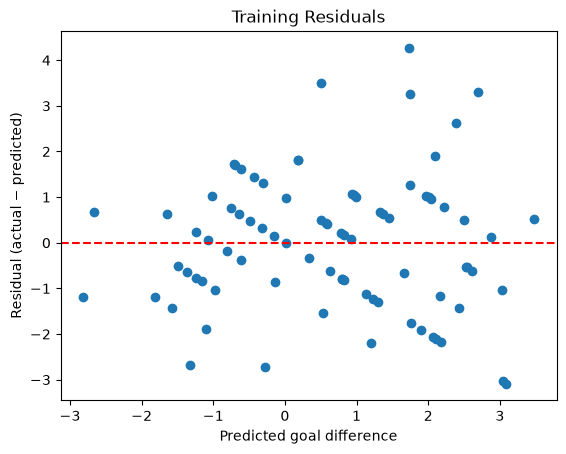

In [28]:
train_predictions = model.predict(X_train)
residuals = y_train - train_predictions

plt.scatter(train_predictions, residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted goal difference")
plt.ylabel("Residual (actual − predicted)")
plt.title("Training Residuals")
plt.show()

### Interpretation of Training Residuals

Residuals appear on both sides of zero, and several large positive residuals are visible. These indicate matches where the model underestimated the actual goal difference by several goals.

The visible points do not show an obvious curved pattern, but this plot alone does not confirm that all regression assumptions are satisfied.

### Checking Residual Normality and Constant Variance
A normal Q-Q plot compares the residuals with a normal distribution, and the Breusch–Pagan test checks whether the spread of residuals changes with the predictors.

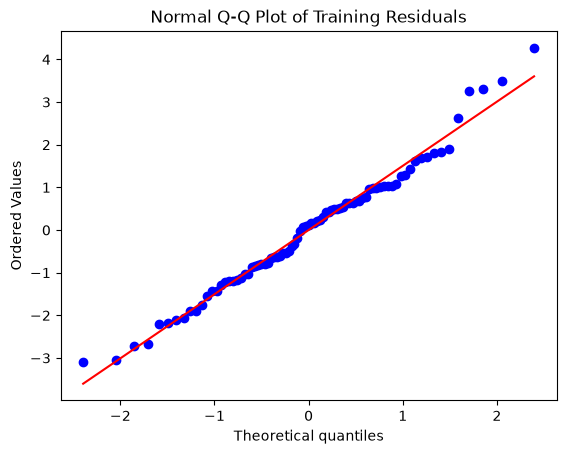

Breusch-Pagan p-value: 0.195


In [29]:
fig, ax = plt.subplots()
stats.probplot(residuals, dist="norm", plot=ax)
plt.title("Normal Q-Q Plot of Training Residuals")
plt.show()

bp_stat, bp_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
print("Breusch-Pagan p-value:", round(bp_p, 3))

### Interpreting Residual Diagnostics

The residuals follow the Q–Q reference line reasonably closely through the middle of the distribution. Some large positive residuals lie above the line, indicating departures in the upper tail. The Jarque–Bera test did not reject normality at the 5% level (p = 0.522).

The Breusch–Pagan p-value was 0.195, so the test did not provide sufficient evidence to reject constant residual variance at the 5% level.

These results do not prove that the assumptions hold. The sample is small, and repeated appearances by the same teams may create dependence between observations.

### Conclusion and Limitations

The eight pre-match predictors explained approximately 49.5% of the variation in training goal difference, with adjusted R² of 0.441. However, prediction performance was weaker on later matches.

Test MAE was 1.214 goals, RMSE was 1.530 goals and R² was 0.002. The regression had lower errors than the training-mean baseline, which achieved MAE of 1.426 and RMSE of 1.747. Nevertheless, the near-zero test R² indicates limited predictive performance.

Rank_Points_Diff was the only individually significant predictor. The exploratory ranking-only model performed slightly better on the same test matches, indicating that the additional predictors did not improve performance on this test set. Match outcomes also depend on factors not represented by these predictors.

**Limitations:**
- The first 24 matches have no earlier tournament history, so their historical differences are 0, meaning no relative information, and are not observed performance.
- Historical measures for later matches are based on relatively few observations.
- The test set contains only 21 matches, all from knockout stages.
- Teams appear in multiple matches, which may create dependence between observations.
- The model predicts continuous goal differences, while actual goal differences are integers.

Overall, FIFA ranking differences showed an association with goal difference, but the model provided limited evidence of reliable prediction for later tournament matches.

## References
- FBref, *2026 World Cup Scores & Fixtures*: https://fbref.com/en/comps/1/schedule/schedule-Stats
- The Stats Don't Lie, *World Cup 2026*: https://www.thestatsdontlie.com/football/world-cup-2026/
- FIFA. (2026). *FIFA/Coca-Cola Men's World Ranking: https://inside.fifa.com/fifa-rankings/world-ranking/men
